<a href="https://colab.research.google.com/github/mraadi-07/CSL701-55_Machine-Learning-Lab/blob/main/MLExp_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Aditya Subhash Thorat

Batch : CS-03


Roll Number : Cs-55



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

# Task 1: Import Libraries and Load Dataset

import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score

# Upload archive.zip in Google Colab
from google.colab import files
uploaded = files.upload()

# Extract the ZIP file
zip_file = "archive.zip"

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("dataset")

# Load the CSV dataset
df = pd.read_csv("dataset/Mall_Customers.csv")

# Display dataset information
print("First 5 rows of the dataset:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())


Saving archive.zip to archive.zip
First 5 rows of the dataset:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40

Dataset shape: (200, 5)

Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Task 2: Feature Selection and Standardization

features = df[["Annual Income (k$)", "Spending Score (1-100)"]]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

print("Original selected features:")
print(features.head())

print("\nScaled features (first 5 rows):")
print(pd.DataFrame(
    X_scaled,
    columns=["Annual Income (Scaled)", "Spending Score (Scaled)"]
).head())

print("\nMean of scaled features:")
print(X_scaled.mean(axis=0))

print("\nStandard deviation of scaled features:")
print(X_scaled.std(axis=0))


Original selected features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40

Scaled features (first 5 rows):
   Annual Income (Scaled)  Spending Score (Scaled)
0               -1.738999                -0.434801
1               -1.738999                 1.195704
2               -1.700830                -1.715913
3               -1.700830                 1.040418
4               -1.662660                -0.395980

Mean of scaled features:
[-2.13162821e-16 -1.46549439e-16]

Standard deviation of scaled features:
[1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

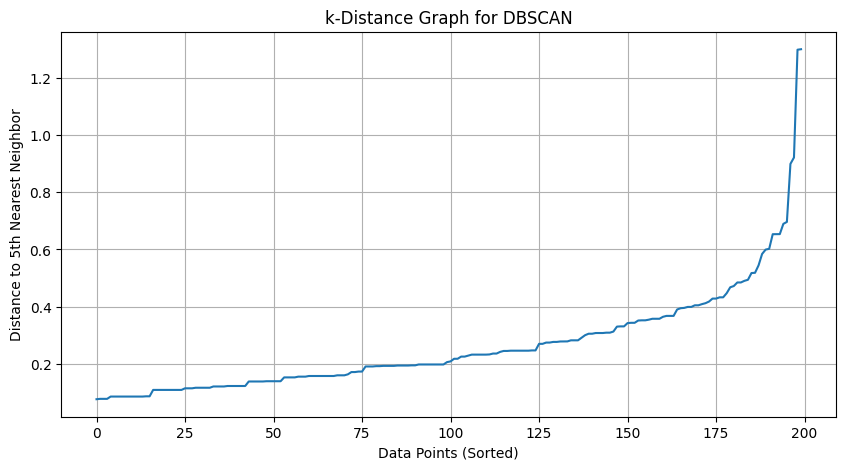

Examine the graph's elbow to select a suitable epsilon.


In [ ]:

# Task 3: Plot the k-Distance Graph

min_samples = 5

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Sort distances to the kth nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.xlabel("Data Points (Sorted)")
plt.ylabel(f"Distance to {min_samples}th Nearest Neighbor")
plt.title("k-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()

print("Examine the graph's elbow to select a suitable epsilon.")


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

In [ ]:

# Task 4: Apply DBSCAN Clustering

eps_value = 0.3  # Adjust based on the k-distance graph

dbscan = DBSCAN(
    eps=eps_value,
    min_samples=min_samples
)

labels = dbscan.fit_predict(X_scaled)

# Add cluster labels to the original dataset
df["Cluster"] = labels

print("Cluster labels for the first 10 customers:")
print(df[["CustomerID", "Annual Income (k$)",
          "Spending Score (1-100)", "Cluster"]].head(10))

print("\nUnique cluster labels:")
print(np.unique(labels))


Cluster labels for the first 10 customers:
   CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
0           1                  15                      39        2
1           2                  15                      81        0
2           3                  16                       6        1
3           4                  16                      77        0
4           5                  17                      40        2
5           6                  17                      76        0
6           7                  18                       6        1
7           8                  18                      94       -1
8           9                  19                       3        1
9          10                  19                      72        0

Unique cluster labels:
[-1  0  1  2  3  4  5  6]


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Task 5: Evaluate DBSCAN Clustering

# Count clusters, excluding noise label -1
n_clusters = len(set(labels) - {-1})

# Count noise points
n_noise = np.sum(labels == -1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)
print("Total data points:", len(labels))

# Calculate Silhouette Score
# Exclude noise points from evaluation
non_noise_mask = labels != -1
X_non_noise = X_scaled[non_noise_mask]
labels_non_noise = labels[non_noise_mask]

if (len(set(labels_non_noise)) >= 2 and
        len(set(labels_non_noise)) < len(labels_non_noise)):
    score = silhouette_score(X_non_noise, labels_non_noise)
    print("Silhouette Score:", round(score, 4))
else:
    print("Silhouette Score cannot be calculated: "
          "at least 2 non-noise clusters are required.")


Number of clusters: 7
Number of noise points: 35
Total data points: 200
Silhouette Score: 0.5243


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Cluster Statistics:
         Customer_Count  Average_Income  Average_Spending
Cluster                                                  
-1                   35           70.60             51.66
 0                   12           23.17             74.58
 1                    5           19.60              6.60
 2                    7           22.43             34.43
 3                   88           55.23             48.58
 4                   30           79.53             83.13
 5                   14           75.93             10.07
 6                    9           88.78             17.00


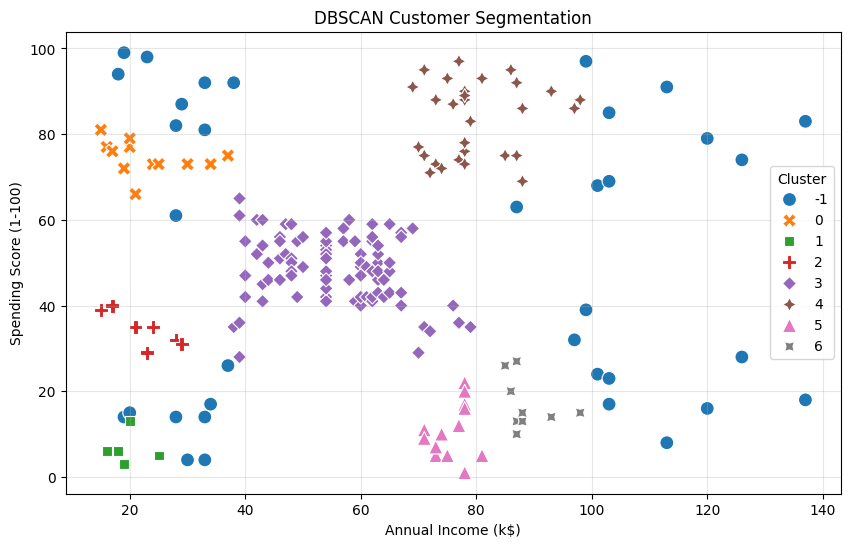


Noise Points:
    CustomerID  Annual Income (k$)  Spending Score (1-100)  Cluster
7            8                  18                      94       -1
10          11                  19                      14       -1
11          12                  19                      99       -1
12          13                  20                      15       -1
19          20                  23                      98       -1
24          25                  28                      14       -1
25          26                  28                      82       -1
27          28                  28                      61       -1
29          30                  29                      87       -1
30          31                  30                       4       -1

Total noise points: 35


In [ ]:

# Task 6: Cluster Statistics

# Calculate statistics for each cluster
cluster_stats = df.groupby("Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

print("Cluster Statistics:")
print(cluster_stats)

# Visualize clusters and noise points
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Cluster",
    palette="tab10",
    style="Cluster",
    s=100
)

plt.title("DBSCAN Customer Segmentation")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.grid(True, alpha=0.3)
plt.show()

# Display noise points
noise_points = df[df["Cluster"] == -1]

print("\nNoise Points:")
print(noise_points[
    ["CustomerID", "Annual Income (k$)",
     "Spending Score (1-100)", "Cluster"]
].head(10))

print("\nTotal noise points:", len(noise_points))


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.